In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import random

import warnings
warnings.filterwarnings('ignore')

def housing_data_reader(filename='normalized_diabetes.csv'):
    data = pd.read_csv(filename)
    X = data.drop(['diabetes'],axis = 1)
    y = data['diabetes']
    return X, y

In [2]:
rsts = {}

rsts['SHAP'] = {
    'SHAP': {
        'values': [
           ('drinking', 0.096905),
            ('HDL', 0.073769),
            ('FFPG', 0.061544),
            ('Age', 0.059428),
            ('smoking', 0.053602),
            ('FPG', 0.053054),
            ('Gender', 0.032942),
            ('family_histroy', 0.029326),
            ('CCR', 0.024757),
            ('Chol', 0.022145),
            ('DBP', 0.010225),
            ('LDL', 0.009465),
            ('ALT', 0.009298),
            ('SBP', 0.004961),
            ('BMI', 0.003737),
            ('BUN', 0.003334),
            ('Tri', 0.001744)
        ],
        'duration': 26.053436279296875
    }
}

rsts['SamplingSHAP'] = {
    'SamplingSHAP': {
        'values': [
           ('drinking', 1.000000),
            ('HDL', 0.583186),
            ('smoking', 0.549665),
            ('FFPG', 0.546067),
            ('Age', 0.486065),
            ('FPG', 0.429538),
            ('Gender', 0.260961),
            ('CCR', 0.187768),
            ('Chol', 0.167165),
            ('family_histroy', 0.165873),
            ('DBP', 0.079558),
            ('LDL', 0.058544),
            ('ALT', 0.057423),
            ('SBP', 0.028448),
            ('BMI', 0.018262),
            ('BUN', 0.012936),
            ('Tri', 0.000000)
        ],
        'duration': 2619.1238548755646
    }
}
rsts['KernelSHAP'] = {
    'KernelSHAP': {
        'values': [
            ('drinking', 0.107832),
            ('HDL', 0.063663),
            ('smoking', 0.059900),
            ('FFPG', 0.059400),
            ('Age', 0.053261),
            ('FPG', 0.047291),
            ('Gender', 0.029727),
            ('CCR', 0.021560),
            ('family_histroy', 0.020029),
            ('Chol', 0.019170),
            ('DBP', 0.009823),
            ('LDL', 0.007515),
            ('ALT', 0.007429),
            ('SBP', 0.004158),
            ('BMI', 0.003056),
            ('BUN', 0.002593),
            ('Tri', 0.001396)
        ],
        'duration': 20929.120724201202
    }
}

rsts['LIME'] = {
    'LIME': {
        'values': [
('drinking', 0.5304152189058157),
            ('smoking', 0.2660179768571671),
            ('family_histroy', 0.2078525100817223),
            ('FPG', 0.10998966424112203),
            ('HDL', 0.0862009291556942),
            ('Gender', 0.08212384370629036),
            ('Age', 0.05174794076345545),
            ('FFPG', 0.029838573698287945),
            ('CCR', 0.02617819319767786),
            ('ALT', 0.023640842798161914),
            ('BUN', 0.0179425603603581),
            ('SBP', 0.011738341306783185),
            ('BMI', 0.011440137005360526),
            ('Chol', 0.010940202854689754),
            ('LDL', 0.00431675044975306),
            ('Tri', 0.003679448310961801),
            ('DBP', 0.003005552081465658)
        ],
        'duration': 0.9115903377532959
    }
}

rsts['Permutation Feature Importance'] = {
    'Permutation Feature Importance': {
        'values': [
               ('drinking', 1.000000),
            ('HDL', 0.672094),
            ('smoking', 0.465733),
            ('FFPG', 0.235161),
            ('FPG', 0.094459),
            ('Age', 0.065782),
            ('Gender', 0.065686),
            ('Chol', 0.032528),
            ('family_histroy', 0.022245),
            ('LDL', 0.017172),
            ('CCR', 0.014762),
            ('BUN', 0.012207),
            ('BMI', 0.008619),
            ('Tri', 0.006574),
            ('SBP', 0.003800),
            ('DBP', 0.001006),
            ('ALT', 0.000000)
        ],
        'duration': 2.5785508155822754
    }
}

rsts['ShapG'] = {
    'ShapG': {
        'values': [
           ('FFPG', 1.294401151649507),
            ('FPG', 0.9879978794365848),
            ('smoking', 0.769373759828738),
            ('HDL', 0.766002992728199),
            ('drinking', 0.7570369240644075),
            ('Age', 0.7030577851878803),
            ('LDL', 0.6332980718240645),
            ('SBP', 0.4302212339268999),
            ('Tri', 0.15672182394887346),
            ('BMI', 0.10788685959023478),
            ('DBP', 0.10065151961384569),
            ('Gender', 0.04332139522034668),
            ('CCR', 0.034117741531562974),
            ('BUN', 0.015933134506325233),
            ('family_histroy', 0.0),
            ('ALT', -0.009432982670893014),
            ('Chol', -0.014957965308319832)
        ],
        'duration': 5736.587858200073
    }
}

rsts['FastSHAP'] = {
    'FastSHAP': {
        'values': [
           ('drinking', 29.049278),
('smoking', 26.995213),
('CCR', 26.198925),
('DBP', 18.526127),
('BUN', 18.264387),
('HDL', 16.534279),
('Chol', 16.286686),
('ALT', 15.67362),
('family_histroy', 15.145338),
('SBP', 14.38582),
('BMI', 13.291111),
('Gender', 12.77313),
('Age', 12.657099),
('LDL', 8.779902),
('Tri', 8.185405),
('FPG', 9.053093),
('FFPG', 7.2268915)
        ],
        'duration': 153.36
    }
}

In [3]:
import pandas as pd

# 提取每个方法的特征排序
methods = {
    'SHAP': [feature for feature, _ in rsts['SHAP']['SHAP']['values']],
     'SamplingSHAP': [feature for feature, _ in rsts['SamplingSHAP']['SamplingSHAP']['values']],
    'KernelSHAP': [feature for feature, _ in rsts['KernelSHAP']['KernelSHAP']['values']],
    'LIME': [feature for feature, _ in rsts['LIME']['LIME']['values']],
    # 'Feature Imoprtance': [feature for feature, _ in rsts['Feature Imoprtance']['Feature Imoprtance']['values']],
    'Permutation Feature Importance': [feature for feature, _ in rsts['Permutation Feature Importance']['Permutation Feature Importance']['values']],
    'ShapG': [feature for feature, _ in rsts['ShapG']['ShapG']['values']],
        'FastSHAP': [feature for feature, _ in rsts['FastSHAP']['FastSHAP']['values']]

}

# 创建 DataFrame
df = pd.DataFrame(methods)

# 显示 DataFrame
df

,SHAP,SamplingSHAP,KernelSHAP,LIME,Permutation Feature Importance,ShapG,FastSHAP
0,drinking,drinking,drinking,drinking,drinking,FFPG,drinking
1,HDL,HDL,HDL,smoking,HDL,FPG,smoking
2,FFPG,smoking,smoking,family_histroy,smoking,smoking,CCR
3,Age,FFPG,FFPG,FPG,FFPG,HDL,DBP
4,smoking,Age,Age,HDL,FPG,drinking,BUN
5,FPG,FPG,FPG,Gender,Age,Age,HDL
6,Gender,Gender,Gender,Age,Gender,LDL,Chol
7,family_histroy,CCR,CCR,FFPG,Chol,SBP,ALT
8,CCR,Chol,family_histroy,CCR,family_histroy,Tri,family_histroy
9,Chol,family_histroy,Chol,ALT,LDL,BMI,SBP


In [4]:
# global mapping of colors and markers
colors = {
    'SHAP': 'c',  
    'SamplingSHAP': 'm',
    'SamplingSHAP (KernelSHAP)': 'm',
    'KernelSHAP': 'purple',
    'LIME': 'g',
    'Feature Imoprtance':'y',
    'Permutation Feature Importance':'b',
    'ShapG': 'r',
    'FastSHAP':'orange'
}
markers = {
    'SHAP': 'o',  
    'SamplingSHAP': '+',
    'SamplingSHAP (KernelSHAP)': '+',
    'KernelSHAP': 's',  # 添加了 KernelSHAP 的标记符号
    'LIME': '^',  # 添加了 LIME 的标记符号
    'Feature Importance': '<',  # 添加了 Feature Importance 的标记符号
    'Permutation Feature Importance': 'v',  # 添加了 Permutation Feature Importance 的标记符号
    'ShapG': '*',
    'FastSHAP': 'X'
}

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,accuracy_score
import lightgbm as lgb

def compute_weighted_slope(metrics, beta=0.8):
    """
    Compute the weighted slope of accuracy changes.

    Parameters:
    - metrics: List of metric values (e.g., accuracy or R^2).
    - beta: Weight decay factor (default: 0.8).

    Returns:
    - slope: Weighted slope value.
    """
    deltas = [metrics[i] - metrics[i + 1] for i in range(len(metrics) - 1)]
    weights = [beta**i for i in range(len(deltas))]
    slope = np.dot(deltas, weights)
    return slope

def plot_feature_dropping_effects(X, y, method2dict, limit=10, plot_title='Comparison of accuracy after dropping features (LightGBM)', filename=None):
    """
    Function to plot the effect on prediction accuracy of dropping features based on various ratios of method2dict.

    Parameters:
    X (DataFrame): Feature matrix.
    y (Series/DataFrame): Target variable.
    method2dict (dict): Dictionary containing feature ranks and other details.
    limit (int): Maximum number of features to drop.
    plot_title (str): Title for the plot.
    filename (str): File name to save the plot (optional).

    Returns:
    results (dict): Dictionary containing the features dropped and corresponding accuracies for each method.
    """
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    seed_value = 42
    random.seed(seed_value)
    np.random.seed(seed_value)
    tf.random.set_seed(seed_value)
    model = Sequential([
                        Dense(64, input_dim=X_train.shape[1], activation='relu'),
                        Dense(64, input_dim=X_train.shape[1], activation='relu'),
                        Dense(32, activation='relu'),
                         Dense(1, activation='sigmoid')
                            ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    model.fit(X_train, y_train, epochs=10, batch_size=10, validation_split=0.2, verbose=0)   
    pred = model.predict(X_test)
    initial_accuracy = accuracy_score(y_test, pred.round())

    results = {}
    plt.figure(figsize=(10, 6))  # 调整图形大小以适应图例

    # Plot for each method
    for method, rst_dict in method2dict.items():
        for k, v in rst_dict.items():
            metrics = [initial_accuracy]
            deltas = []
            feature_rank = [x[0] for x in v['values']]

            # Drop features and calculate accuracy
            for i in range(1, limit):
                features_to_drop = feature_rank[:i]
                reduced_X = X.drop(columns=features_to_drop)
            

                X_train, X_test, y_train, y_test = train_test_split(reduced_X, y, test_size=0.2, random_state=42)
                seed_value = 42
                random.seed(seed_value)
                np.random.seed(seed_value)
                tf.random.set_seed(seed_value)
                model = Sequential([
                        Dense(64, input_dim=X_train.shape[1], activation='relu'),
                        Dense(64, input_dim=X_train.shape[1], activation='relu'),
                        Dense(32, activation='relu'),
                         Dense(1, activation='sigmoid')
                            ])
                model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

                model.fit(X_train, y_train, epochs=10, batch_size=10, validation_split=0.2, verbose=0)
                pred = model.predict(X_test)
                new_accuracy = accuracy_score(y_test, pred.round())

                deltas.append(metrics[-1] - new_accuracy)
                metrics.append(new_accuracy)

            # Compute weighted slope
            slope = compute_weighted_slope(metrics)

            # Store results
            results[k] = {
                'Features': feature_rank,
                'Metrics': metrics,
                'S': slope
            }

            # Plot with method-specific color and marker
            label = f'{k} (S: {slope:.4f})'
            plt.plot(
                range(0, limit), 
                metrics, 
                marker=markers.get(method, 'o'), 
                color=colors.get(method, 'k'),
                label=label, 
                linewidth=1.5, 
                alpha=0.7
            )

    # Customize plot
    plt.xlabel('Number of Features Dropped')
    plt.ylabel('Accuracy')
    # plt.title(plot_title)
    plt.xticks(range(0, limit))
    plt.grid()

    # Place legend inside the plot
    plt.legend(loc='lower left', fontsize='small', frameon=True)

    # Save plot if filename is provided
    if filename:
        plt.savefig(filename, format='eps', dpi=300, bbox_inches='tight')

    plt.show()

    return results

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 621us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 629us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 636us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 612us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 682us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 641us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 646us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 622us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 628us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 763us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 643us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 669us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 654us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 657us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 645us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 669us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 635us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 624us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 636us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 646us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 644us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 665us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 645us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 631us/step
27/27 ━━━━━━━━━━

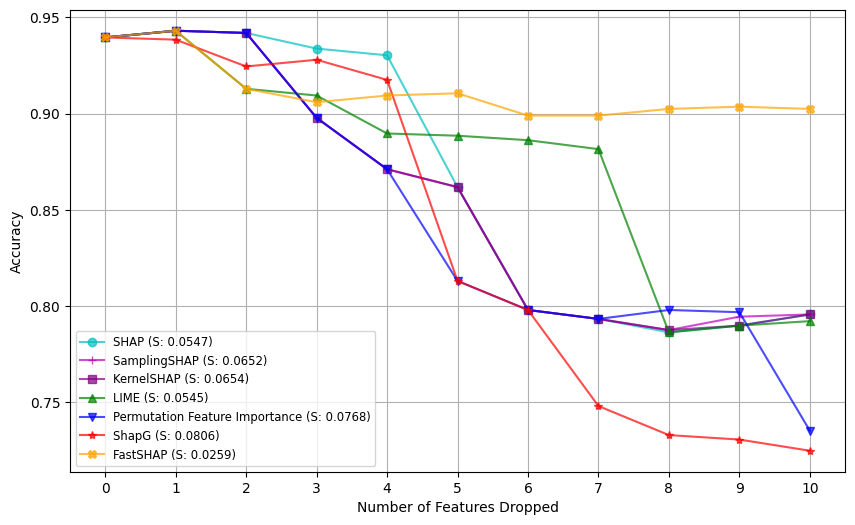


各方法的 Slope 和 Duration:
SHAP: Slope=0.0547, Duration=26.0534s
SamplingSHAP: Slope=0.0652, Duration=2619.1239s
KernelSHAP: Slope=0.0654, Duration=20929.1207s
LIME: Slope=0.0545, Duration=0.9116s
Permutation Feature Importance: Slope=0.0768, Duration=2.5786s
ShapG: Slope=0.0806, Duration=5736.5879s
FastSHAP: Slope=0.0259, Duration=153.3600s


In [6]:
X, y = housing_data_reader('normalized_diabetes.csv')

results =  plot_feature_dropping_effects(X, y, rsts, limit=11, filename='Compare-diabetes-nn-n.eps')  
# plot_feature_dropping_effects(X, y, rsts, limit=11)  
combined_results = {}
for method_name, result_dict in results.items():
    # 从原始 rsts 中获取 duration
    duration = None
    for key, val in rsts.items():
        if method_name in val:
            duration = val[method_name]['duration']
            break
    
    combined_results[method_name] = {
        'Slope': result_dict['S'],
        'duration': duration,
        'Metrics': result_dict['Metrics'],
        'Features': result_dict['Features']
    }

print("\n各方法的 Slope 和 Duration:")
for method, data in combined_results.items():
    print(f"{method}: Slope={data['Slope']:.4f}, Duration={data['duration']:.4f}s")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


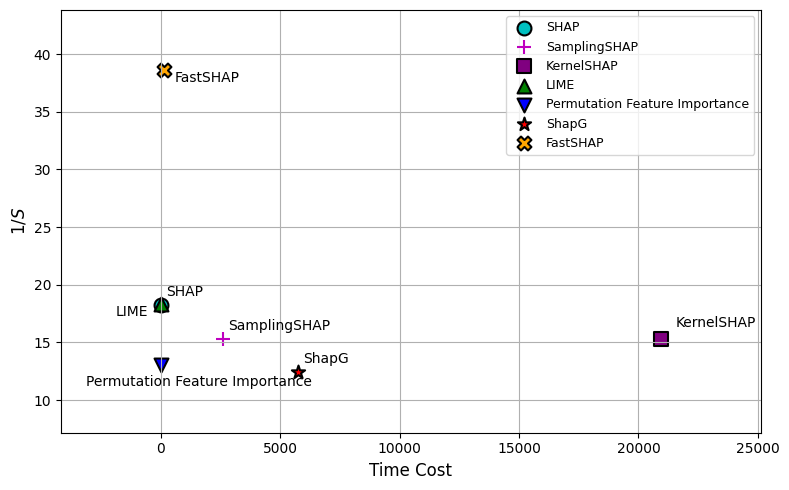

In [7]:
def plot_by_triple(triple, title='Comparison of Time Cost and $1/S$', filename=None):
    fig, ax = plt.subplots(figsize=(8, 5))
    
    # 准备数据
    x = [t[1] for t in triple]
    y = [1/t[0] for t in triple]
    labels = [t[2] for t in triple]
    
    # 计算数据范围
    x_range = max(x) - min(x)
    y_range = max(y) - min(y)
    
    # 设置适当的边距
    margin = 0.2
    ax.set_xlim(min(x) - margin * x_range, max(x) + margin * x_range)
    ax.set_ylim(min(y) - margin * y_range, max(y) + margin * y_range)
    
    # 绘制散点，使用全局定义的 colors 和 markers
    for i, txt in enumerate(labels):
        ax.scatter(
            x[i],
            y[i],
            color=colors.get(txt, 'k'),
            marker=markers.get(txt, 'o'),
            edgecolors='black',
            s=100,
            linewidths=1.5,
            label=txt
        )
    
    # 为每个方法手动设置标签偏移位置，避免重叠
    label_offsets = {
        'SHAP': (0.01, 0.02),
        'SamplingSHAP':(0.01, 0.02),
        'LIME': (-0.09, -0.05),
        'Permutation Feature Importance': (-0.15, -0.08),
        'ShapG': (0.01, 0.02),
        'FastSHAP': (0.02, -0.05)
    }
    
    # 添加文本标签 (使用text代替annotate以避免EPS保存问题)
    for i, txt in enumerate(labels):
        offset_x_ratio, offset_y_ratio = label_offsets.get(txt, (0.03, 0.03))
        offset_x = x_range * offset_x_ratio
        offset_y = y_range * offset_y_ratio
        
        ax.text(
            x[i] + offset_x,
            y[i] + offset_y,
            txt,
            fontsize=10,
            color='black',
            horizontalalignment='left',
            verticalalignment='bottom'
        )
    
    
    ax.set_xlabel('Time Cost', fontsize=12)
    ax.set_ylabel('$1/S$', fontsize=12)
    # ax.set_title(title, fontsize=14)
    ax.legend(fontsize=9, loc='best', frameon=True)
    ax.grid(True)  # 移除alpha参数
    
    plt.tight_layout()
    
    # 使用fig.savefig确保保存当前图形
    if filename:
        fig.savefig(filename, format='eps', dpi=300, bbox_inches='tight')
    
    plt.show()
    
    return fig

def plot_by_rsts(rsts, title='Comparison of Time Cost and $1/S$', filename=None):
    """
    rsts: dict of results
    """
    triple = []
    for method, data in rsts.items():
        slope = data['Slope']
        time = data['duration']
        triple.append((slope, time, method))
    plot_by_triple(triple, title, filename)


plot_by_rsts(combined_results, filename='Time-Vs-S-diabetes-fnn.eps')

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


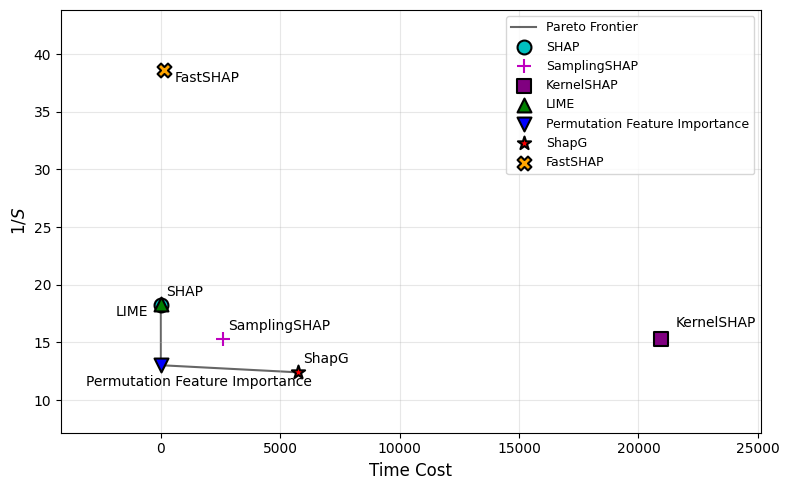

In [9]:
def compute_pareto_frontier(points):
    """
    Compute Pareto frontier for minimization of both x (Time Cost) and y (1/S).
    points: list of (x, y, label) tuples
    Returns list of Pareto optimal points sorted by x.
    """
    pareto = []
    for i, (x1, y1, lbl1) in enumerate(points):
        dominated = False
        for j, (x2, y2, _) in enumerate(points):
            if i != j and x2 <= x1 and y2 <= y1 and (x2 < x1 or y2 < y1):
                dominated = True
                break
        if not dominated:
            pareto.append((x1, y1, lbl1))
    pareto.sort(key=lambda p: p[0])
    return pareto


def plot_by_rsts_pareto(rsts, title='Comparison of Time Cost and $1/S$', filename=None):
    """
    Same as plot_by_rsts but with Pareto frontier connecting the non-dominated points.
    """
    triple = []
    for method, data in rsts.items():
        slope = data['Slope']
        time = data['duration']
        triple.append((slope, time, method))

    fig, ax = plt.subplots(figsize=(8, 5))

    x = [t[1] for t in triple]
    y = [1 / t[0] for t in triple]
    labels = [t[2] for t in triple]

    x_range = max(x) - min(x)
    y_range = max(y) - min(y)

    margin = 0.2
    ax.set_xlim(min(x) - margin * x_range, max(x) + margin * x_range)
    ax.set_ylim(min(y) - margin * y_range, max(y) + margin * y_range)

    # --- Pareto frontier ---
    points = list(zip(x, y, labels))
    pareto = compute_pareto_frontier(points)
    px = [p[0] for p in pareto]
    py = [p[1] for p in pareto]
    ax.plot(px, py, 'k-', linewidth=1.5, alpha=0.6, zorder=1, label='Pareto Frontier')

    # --- Scatter all points ---
    for i, txt in enumerate(labels):
        ax.scatter(
            x[i], y[i],
            color=colors.get(txt, 'k'),
            marker=markers.get(txt, 'o'),
            edgecolors='black',
            s=100,
            linewidths=1.5,
            label=txt,
            zorder=2
        )
    label_offsets = {
       'SHAP': (0.01, 0.02),
        'SamplingSHAP':(0.01, 0.02),
        'LIME': (-0.09, -0.05),
        'Permutation Feature Importance': (-0.15, -0.08),
        'ShapG': (0.01, 0.02),
        'FastSHAP': (0.02, -0.05)
    }
    
    # 添加文本标签
    for i, txt in enumerate(labels):
        offset_x_ratio, offset_y_ratio = label_offsets.get(txt, (0.03, 0.03))
        offset_x = x_range * offset_x_ratio
        offset_y = y_range * offset_y_ratio
        
        ax.text(
            x[i] + offset_x,
            y[i] + offset_y,
            txt,
            fontsize=10,
            color='black',
            horizontalalignment='left',
            verticalalignment='bottom'
        )

    ax.set_xlabel('Time Cost', fontsize=12)
    ax.set_ylabel('$1/S$', fontsize=12)
    ax.legend(fontsize=9, loc='best')
    ax.grid(alpha=0.3)

    plt.tight_layout()

    if filename:
        plt.savefig(filename, format='eps', dpi=300, bbox_inches='tight')

    plt.show()

plot_by_rsts_pareto(combined_results, filename='Time-Vs-S-diabetes-FNN-Pareto.eps')
# plot_by_rsts_pareto(combined_results)
